# 01 — Exploration des données MVTec AD
**Sujet 16 : Visual Anomaly Detection** — catégories étudiées : `bottle`, `hazelnut`, `carpet`.

Objectifs de ce notebook :
1. Connaître les effectifs (apprentissage / validation / test) et les types de défauts.
2. Visualiser des exemples sains et défectueux avec leurs masques.
3. Étudier les **histogrammes d'intensité** (Ch. 2) : suffisent-ils à séparer sain / défaut ?
4. Mesurer la **variabilité de position** des images saines → justifier l'**alignement spatial**.
5. Mesurer la taille des défauts (masques) → choisir la taille des zones d'analyse.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.data_loader import load_config, get_splits, load_image, load_mask

cfg = load_config(ROOT / "config.yaml")
CATS = cfg["data"]["categories"]
OUT = ROOT / "results" / "01_exploration"; OUT.mkdir(parents=True, exist_ok=True)
S = 256  # taille de travail pour l'exploration (INTER_AREA = anti-repliement, Ch. 2)
splits = {c: get_splits(c, cfg) for c in CATS}

def gray(sample, size=S):
    return cv2.resize(load_image(sample.path, grayscale=True), (size, size), interpolation=cv2.INTER_AREA)
def rgb(sample, size=S):
    return cv2.cvtColor(cv2.resize(load_image(sample.path), (size, size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
print("Catégories :", CATS)

Catégories : ['bottle', 'hazelnut', 'carpet']


## 1. Effectifs

In [2]:
rows = []
for c in CATS:
    s = splits[c]
    rows.append({"catégorie": c, "train (sain)": len(s["train"]), "validation (sain)": len(s["val"]),
                 "test normales": sum(x.label == 0 for x in s["test"]),
                 "test anomalies": sum(x.label == 1 for x in s["test"]),
                 "taille originale": "x".join(map(str, load_image(s["train"][0].path).shape[:2]))})
df_counts = pd.DataFrame(rows).set_index("catégorie")
df_counts.to_csv(OUT / "effectifs.csv"); df_counts

,train (sain),validation (sain),test normales,test anomalies,taille originale
catégorie,,,,,
bottle,167,42,20,63,900x900
hazelnut,313,78,40,70,1024x1024
carpet,224,56,28,89,1024x1024


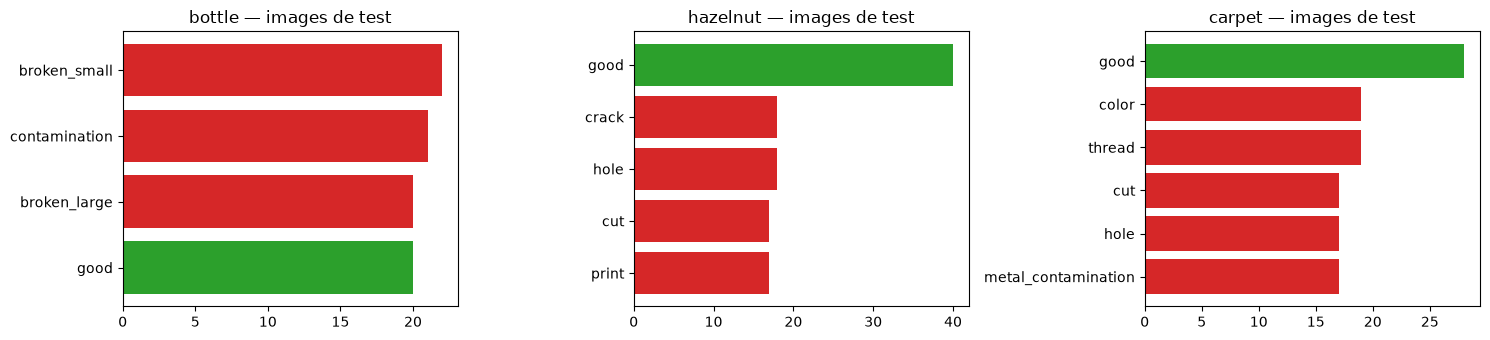

In [3]:
fig, axes = plt.subplots(1, len(CATS), figsize=(5 * len(CATS), 3.5))
for ax, c in zip(axes, CATS):
    d = pd.Series([x.defect for x in splits[c]["test"]]).value_counts()
    colors = ["tab:green" if k == "good" else "tab:red" for k in d.index]
    ax.barh(d.index, d.values, color=colors); ax.set_title(f"{c} — images de test"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(OUT / "repartition_defauts.png", dpi=120); plt.show()

## 2. Exemples : images saines et défauts (masque en rouge)

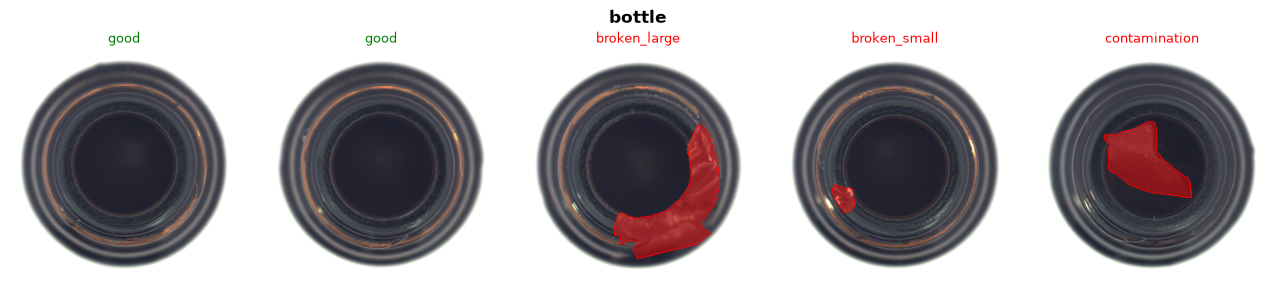

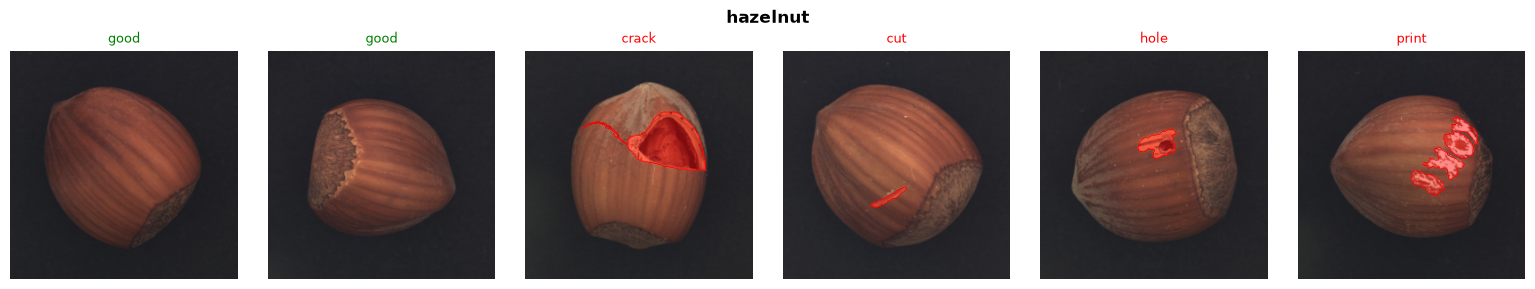

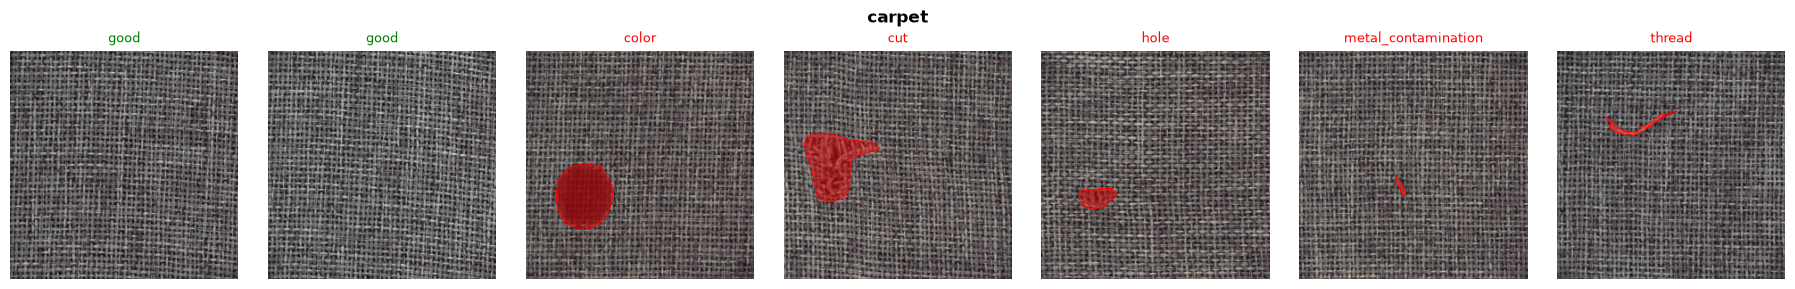

In [4]:
def overlay(img, mask, alpha=0.45):
    out = img.copy().astype(np.float32)
    m = mask.astype(bool)
    out[m] = (1 - alpha) * out[m] + alpha * np.array([255, 0, 0])
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = out.astype(np.uint8); cv2.drawContours(out, cnts, -1, (255, 0, 0), 1)
    return out

for c in CATS:
    test = splits[c]["test"]
    defects = sorted({x.defect for x in test if x.label == 1})
    picks = splits[c]["train"][:2] + [next(x for x in test if x.defect == d) for d in defects]
    fig, axes = plt.subplots(1, len(picks), figsize=(2.6 * len(picks), 2.9))
    for ax, x in zip(axes, picks):
        im = rgb(x)
        if x.label:
            m = cv2.resize(load_mask(x), (S, S), interpolation=cv2.INTER_NEAREST)  # nearest pour un masque (Ch. 2)
            im = overlay(im, m)
        ax.imshow(im); ax.set_title(x.defect, fontsize=9, color="green" if x.label == 0 else "red"); ax.axis("off")
    fig.suptitle(c, fontweight="bold"); plt.tight_layout()
    plt.savefig(OUT / f"exemples_{c}.png", dpi=120); plt.show()

## 3. Histogrammes d'intensité (Ch. 2)
Histogramme normalisé $H_n(k) = H(k)/N$ sur 64 intervalles. On compare l'histogramme moyen des images saines à celui des images défectueuses, puis on teste un détecteur naïf : **distance de Bhattacharyya** entre l'histogramme **global** d'une image et l'histogramme moyen sain. Si l'AUROC est proche de 0,5, l'histogramme global ne suffit pas → il faut des histogrammes **par zone**.

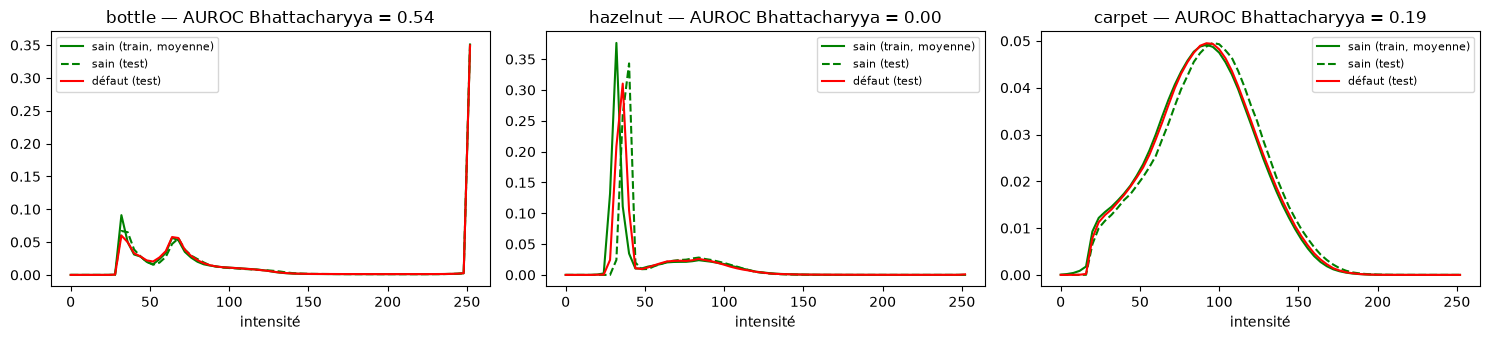

,AUROC histogramme global
catégorie,
bottle,0.540
hazelnut,0.001
carpet,0.193


In [5]:
BINS = 64
def hist(img):
    h = cv2.calcHist([img], [0], None, [BINS], [0, 256]).ravel()
    return h / h.sum()

hist_rows = []
fig, axes = plt.subplots(1, len(CATS), figsize=(5 * len(CATS), 3.5))
for ax, c in zip(axes, CATS):
    s = splits[c]
    H_train = np.array([hist(gray(x)) for x in s["train"]])
    ref = H_train.mean(0).astype(np.float32)
    H_test = np.array([hist(gray(x)) for x in s["test"]]); y = np.array([x.label for x in s["test"]])
    d = np.array([cv2.compareHist(ref, h.astype(np.float32), cv2.HISTCMP_BHATTACHARYYA) for h in H_test])
    auc = roc_auc_score(y, d)
    hist_rows.append({"catégorie": c, "AUROC histogramme global": round(auc, 3)})
    x = np.arange(BINS) * 256 / BINS
    ax.plot(x, ref, "g", label="sain (train, moyenne)")
    ax.plot(x, H_test[y == 0].mean(0), "g--", label="sain (test)")
    ax.plot(x, H_test[y == 1].mean(0), "r", label="défaut (test)")
    ax.set_title(f"{c} — AUROC Bhattacharyya = {auc:.2f}"); ax.set_xlabel("intensité"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "histogrammes.png", dpi=120); plt.show()
df_hist = pd.DataFrame(hist_rows).set_index("catégorie"); df_hist.to_csv(OUT / "auroc_histogramme_global.csv"); df_hist

## 3 bis. Diagnostic : pourquoi une AUROC *inférieure* à 0,5 ?
Une AUROC de 0,00 (hazelnut) signifie que les images **saines du test** sont plus éloignées de la référence que les images défectueuses. On compare donc la distance à l'histogramme de référence pour chaque sous-ensemble, et l'intensité moyenne.

In [6]:
diag = []
for c in CATS:
    s = splits[c]
    ref = np.array([hist(gray(x)) for x in s["train"]]).mean(0).astype(np.float32)
    groups = {"train": s["train"], "validation": s["val"],
              "test sain": [x for x in s["test"] if x.label == 0], "test défaut": [x for x in s["test"] if x.label == 1]}
    for name, L in groups.items():
        ims = [gray(x) for x in L]
        dd = [cv2.compareHist(ref, hist(im).astype(np.float32), cv2.HISTCMP_BHATTACHARYYA) for im in ims]
        diag.append({"catégorie": c, "sous-ensemble": name, "distance Bhattacharyya moy.": round(float(np.mean(dd)), 3),
                     "intensité moyenne": round(float(np.mean([im.mean() for im in ims])), 1),
                     "fond (5e centile)": round(float(np.mean([np.percentile(im, 5) for im in ims])), 1)})
df_diag = pd.DataFrame(diag).set_index(["catégorie", "sous-ensemble"]); df_diag.to_csv(OUT / "diagnostic_decalage.csv"); df_diag

distance Bhattacharyya moy.  intensité moyenne  \
catégorie sous-ensemble                                                   
bottle    train                                0.048              136.4   
          validation                           0.048              136.1   
          test sain                            0.071              137.7   
          test défaut                          0.091              137.7   
hazelnut  train                                0.228               51.0   
          validation                           0.220               50.6   
          test sain                            0.530               55.8   
          test défaut                          0.344               53.7   
carpet    train                                0.042               90.4   
          validation                           0.044               90.9   
          test sain                            0.064               94.6   
          test défaut                          0.048               91.7   

                         fond (5e centile)  
catégorie sous-ensemble                     
bottle    train                       34.3  
          validation                  34.3  
          test sain                   35.0  
          test défaut                 36.4  
hazelnut  train                       30.4  
          validation                  30.1  
          test sain                   36.6  
          test défaut                 33.4  
carpet    train                       34.8  
          validation                  35.0  
          test sain                   38.1  
          test défaut                 36.6

## 4. Variabilité de position des images saines → faut-il aligner ?
Image moyenne et écart-type pixel à pixel sur les images saines d'apprentissage. Un objet toujours au même endroit donne une moyenne **nette** et un écart-type **faible** ; un objet qui tourne/se déplace donne une moyenne **floue** et un écart-type **fort** sur les bords.

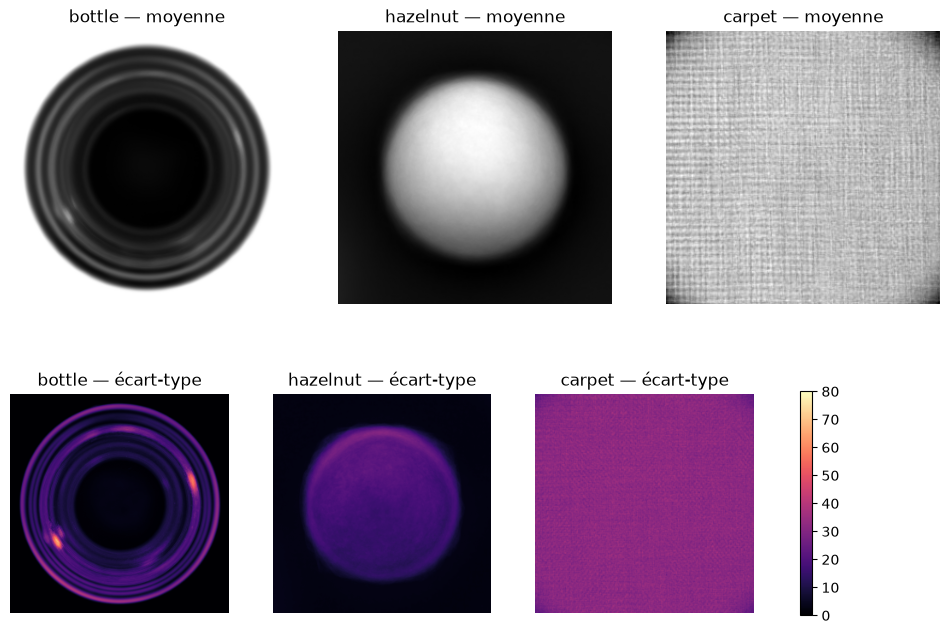

,écart-type moyen (niveaux de gris),écart-type max
catégorie,,
bottle,7.3,66.8
hazelnut,9.0,30.8
carpet,31.8,37.3


In [7]:
var_rows = []
fig, axes = plt.subplots(2, len(CATS), figsize=(4 * len(CATS), 8))
for j, c in enumerate(CATS):
    stack = np.array([gray(x) for x in splits[c]["train"]], dtype=np.float32)
    mean, std = stack.mean(0), stack.std(0)
    var_rows.append({"catégorie": c, "écart-type moyen (niveaux de gris)": round(float(std.mean()), 1),
                     "écart-type max": round(float(std.max()), 1)})
    axes[0, j].imshow(mean, cmap="gray"); axes[0, j].set_title(f"{c} — moyenne"); axes[0, j].axis("off")
    im = axes[1, j].imshow(std, cmap="magma", vmin=0, vmax=80); axes[1, j].set_title(f"{c} — écart-type"); axes[1, j].axis("off")
fig.colorbar(im, ax=axes[1, :].tolist(), shrink=0.8)
plt.savefig(OUT / "variabilite_position.png", dpi=120); plt.show()
df_var = pd.DataFrame(var_rows).set_index("catégorie"); df_var.to_csv(OUT / "variabilite.csv"); df_var

## 5. Taille des défauts
Pourcentage de la surface de l'image couvert par le défaut (d'après les masques). Avec une grille 8×8, une zone représente **1/64 ≈ 1,56 %** de l'image.

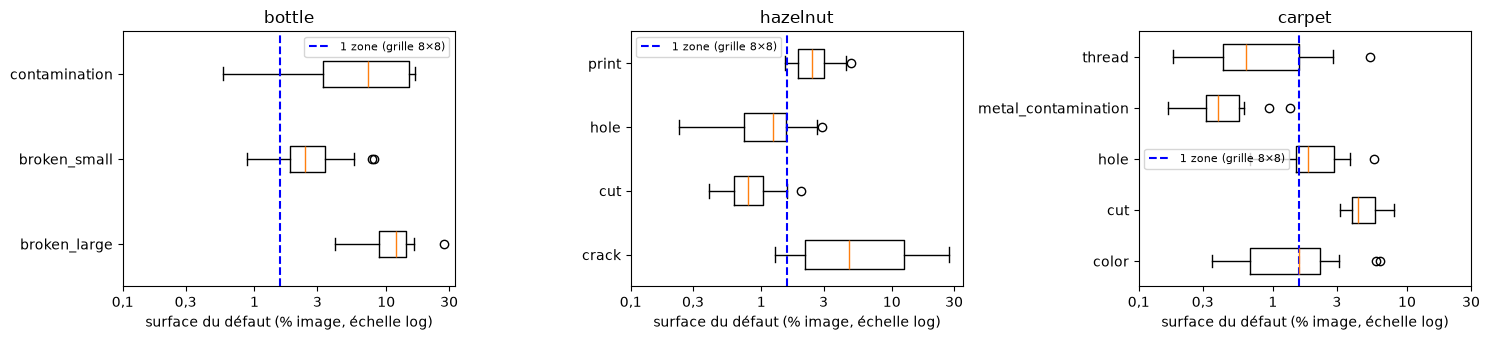

count   min    50%    max
catégorie défaut                                        
bottle    broken_large          20.0  4.09  11.87  27.42
          broken_small          22.0  0.88   2.44   8.06
          contamination         21.0  0.58   7.25  16.53
carpet    color                 19.0  0.35   1.57   6.27
          cut                   17.0  3.18   4.35   8.02
          hole                  17.0  0.67   1.84   5.64
          metal_contamination   17.0  0.16   0.39   1.35
          thread                19.0  0.18   0.64   5.32
hazelnut  crack                 18.0  1.28   4.70  27.66
          cut                   17.0  0.40   0.79   2.02
          hole                  18.0  0.23   1.24   2.93
          print                 17.0  1.52   2.44   4.83

In [8]:
size_rows = []
for c in CATS:
    for x in splits[c]["test"]:
        if x.label:
            m = load_mask(x); size_rows.append({"catégorie": c, "défaut": x.defect, "surface %": 100 * m.mean()})
df_size = pd.DataFrame(size_rows)
fig, axes = plt.subplots(1, len(CATS), figsize=(5 * len(CATS), 3.5))
for ax, c in zip(axes, CATS):
    sub = df_size[df_size["catégorie"] == c]; ds = sorted(sub["défaut"].unique())
    ax.boxplot([sub[sub["défaut"] == d]["surface %"] for d in ds], tick_labels=ds, orientation="horizontal")
    ax.axvline(100 / 64, color="b", ls="--", label="1 zone (grille 8×8)"); ax.set_xscale("log")
    ax.set_xticks([0.1, 0.3, 1, 3, 10, 30]); ax.set_xticklabels(["0,1", "0,3", "1", "3", "10", "30"]); ax.minorticks_off()
    ax.set_title(c); ax.set_xlabel("surface du défaut (% image, échelle log)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "taille_defauts.png", dpi=120); plt.show()
stats = df_size.groupby(["catégorie", "défaut"])["surface %"].describe()[["count", "min", "50%", "max"]].round(2)
stats.to_csv(OUT / "taille_defauts.csv"); stats

In [9]:
print("Part des défauts plus petits qu'une zone 8x8 (1,56 %) :")
print((df_size.assign(petit=df_size["surface %"] < 100/64).groupby("catégorie")["petit"].mean() * 100).round(1).astype(str) + " %")

Part des défauts plus petits qu'une zone 8x8 (1,56 %) :
catégorie
bottle       7.9 %
carpet      52.8 %
hazelnut    44.3 %
Name: petit, dtype: str


## 6. Conclusions pour la suite du projet

**1. L'histogramme global ne suffit pas** (AUROC bottle ≈ 0,54, soit le hasard). Un défaut occupe souvent moins de 5 % de l'image : il ne modifie presque pas l'histogramme de l'image entière. Il faut donc des **histogrammes par zone** (grille), conformément au sujet (« histogrammes d'intensité sur des zones spécifiques »).

**2. Il y a un décalage d'acquisition entre `train/good` et `test`** (hazelnut, et carpet dans une moindre mesure). Le fond des images de test est plus clair (pic de l'histogramme décalé d'environ 32 à 40). La validation, tirée de `train/good`, ne présente pas ce décalage. Un modèle fondé sur les intensités **brutes** classerait donc les noix saines du test comme anomalies, d'où l'AUROC inversée. **Conséquence pour l'étape 4 :** ajouter une **normalisation photométrique** par image (Ch. 2 : normalisation ou égalisation d'histogramme, CLAHE, ou standardisation moyenne/écart-type), et vérifier son effet sur ce diagnostic.

**3. Alignement :**
- *bottle* : position stable, mais l'écart-type est élevé sur les anneaux, signe d'une légère rotation ou d'un décentrage. Un alignement fin est utile.
- *hazelnut* : l'image moyenne est floue (la noix change d'orientation) et l'écart-type est fort sur le contour. L'**alignement est indispensable**. Comme la noix peut tourner de n'importe quel angle, il faut un recalage par rotation (ORB et RANSAC).
- *carpet* : l'écart-type est uniforme, il n'y a pas d'objet à positionner. **Pas d'alignement** : c'est une texture.

**4. Taille des défauts :** la moitié des défauts de carpet et de hazelnut sont plus petits qu'une zone de la grille 8×8 (1,56 % de l'image). Une grille 8×8 avec des zones qui **se chevauchent** (pas de 1/2 zone), ou une grille 16×16, est donc préférable. Ce choix sera évalué lors de l'ablation.